In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths

In [2]:
df = pd.read_csv('Opto_ScoreHalves.csv')
df = df.drop('Cups_Hab', 1)
print(df)

    Group  Cups_Recall  Social_Recall Control
0       1     0.004667      -0.292000       y
1       2     0.189333       0.592667       n
2       3    -0.082000       0.892000       y
3       4    -0.213333      -0.079333       y
4       5     0.176667       0.610667       n
5       6    -0.106000       0.171333       y
6       7    -0.062667       0.044267       y
7       8     0.062000       0.297333       n
8       9     0.045000       0.613400       n
9      10    -0.037467       0.091333       n
10     11    -0.091333       0.130667       y
11     12    -0.035133       0.835333       n
12     13     0.203333      -0.044200       y
13     14     0.294000       0.754667       y
14     15     0.118000       0.032667       y
15     16    -0.124000      -0.108000       y
16     17    -0.042000       0.760580       n
17     18     0.142047       0.560933       n
18     19     0.093333       0.381000       y
19     20     0.014400       0.027667       y
20     21    -0.105193       0.449

/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_40630/3963950884.py:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  df = df.drop('Cups_Hab', 1)


In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
print(newdf)

   Experimental Condition  Left preference control
0             Cups_Recall         0.004667       y
1             Cups_Recall         0.189333       n
2             Cups_Recall        -0.082000       y
3             Cups_Recall        -0.213333       y
4             Cups_Recall         0.176667       n
5             Cups_Recall        -0.106000       y
6             Cups_Recall        -0.062667       y
7             Cups_Recall         0.062000       n
8             Cups_Recall         0.045000       n
9             Cups_Recall        -0.037467       n
10            Cups_Recall        -0.091333       y
11            Cups_Recall        -0.035133       n
12            Cups_Recall         0.203333       y
13            Cups_Recall         0.294000       y
14            Cups_Recall         0.118000       y
15            Cups_Recall        -0.124000       y
16            Cups_Recall        -0.042000       n
17            Cups_Recall         0.142047       n
18            Cups_Recall      

0.6512


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


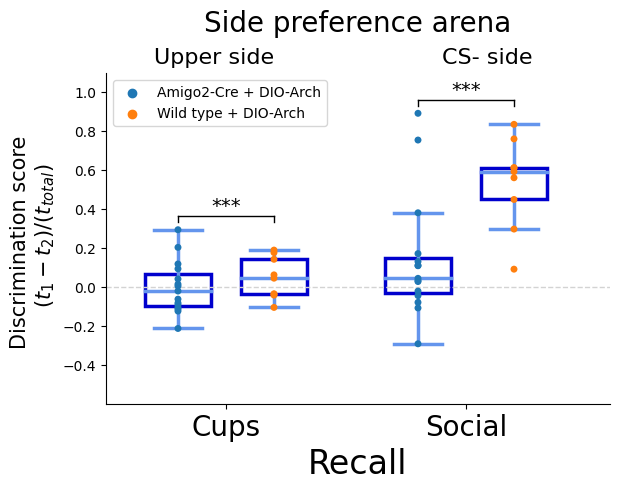

In [4]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue'},
    'medianprops':{'color':'cornflowerblue'},
    'whiskerprops':{'color':'cornflowerblue'},
    'capprops':{'color':'cornflowerblue'}
}

text_boxplot = ['***','***']

type_max = newdf.max(axis=0)['control'];

if (type_max=='y'):
    horder = ['y','n']
else:
    horder = ['n','y']

sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    hue_order=horder,
    jitter=0,
    dodge=True
).axhline(linewidth=1, color='lightgrey',ls='--')

#plt.axvline(x=0.5,linewidth=1, color='red',ls='--')

ax = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    hue_order=horder,
    palette="Set3",
    fliersize=0,
    linewidth=2.5,
    **PROPS
)


data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

#data_ratio = ax.get_data_ratio()
print(ax.get_data_ratio())
handles, labels = ax.get_legend_handles_labels()

if (handles[0].get_label()=='y'):
    arr_legend = ["Amigo2-Cre + DIO-Arch", "Wild type + DIO-Arch"] 
    #arr_legend = ["Controls", "CA2 silenced"] 
    #arr_legend = ["Controls", "CA2 silenced"] 
else:
    arr_legend = ["Amigo2-Cre(-/-)","Amigo2-Cre"]
    
    
l = plt.legend(handles[0:2], arr_legend,loc="upper left")

ax.set_xticklabels(['Cups','Social'], fontsize = 14)


ax.set_xticklabels(['Cups','Social'], fontsize = 20)
ax.text(-0.3,1.15,'Upper side', fontsize = 16)
ax.text(0.9,1.15,'CS- side', fontsize = 16)
ax.set_xlabel("Recall",fontsize=24)
ax.set_ylabel('Discrimination score \n $(t_{1}-t_{2})/(t_{total})$', fontsize = 15)



ax.set_ylim([-0.5999,1.1])
ax.set_xlim([-0.5,1.6])

plt.title("Side preference arena", fontsize=20,y=1.1)

significance(ax,0,data_ratio,newdf.loc[newdf['Experimental Condition']=='Cups_Recall']['Left preference'].max(),text=text_boxplot[0])
significance(ax,1,data_ratio,newdf.loc[newdf['Experimental Condition']=='Social_Recall']['Left preference'].max(),text=text_boxplot[1])

fig = ax.get_figure()

adjust_box_widths(fig, 0.7)
fig.set_size_inches(6.3,5)

plt.tight_layout()
fig.tight_layout()

fig.savefig("Fig5Opto.jpg",dpi=500,bbox_inches='tight')
plt.savefig('Fig5Opto.eps', format='eps')


chile = fig.get_children()[1].get_children()



In [5]:
newdf

,Experimental Condition,Left preference,control
0,Cups_Recall,0.004667,y
1,Cups_Recall,0.189333,n
2,Cups_Recall,-0.082000,y
3,Cups_Recall,-0.213333,y
4,Cups_Recall,0.176667,n
5,Cups_Recall,-0.106000,y
6,Cups_Recall,-0.062667,y
7,Cups_Recall,0.062000,n
8,Cups_Recall,0.045000,n
9,Cups_Recall,-0.037467,n


In [89]:
idk = ax.get_data_ratio()

In [90]:
idk

0.4411470588235294

In [20]:
xaxs.get_tick_padding()

3.5

0.7606666667